# A04 organoid overview — NF-κB pathway heatmap, top-regulated heatmap, PCA
### for Sara & Franzi · organoid / *C. difficile* / butyrate dataset only

**Dataset:** human colonic organoid (single donor), 6 conditions × 3 replicates = 18 samples.
Conditions: Mock 0/5/10 mM butyrate, Cd 0/5/10 mM butyrate (M0/M5/M10, Cd0/Cd5/Cd10 · R1–R3).
This notebook uses **only** the organoid dataset (no HT29 / co-infection here).

---
### Intro
The A04 organoid experiment dials sodium-butyrate (0/5/10 mM) against *C. difficile* infection
to test how the metabolite reshapes the host response — in particular the NF-κB inflammatory
programme (the IL-8/chemokine "brake" we characterised) and the coupled chaperone arm. Before the
targeted analyses, these three overview plots orient the whole dataset: which conditions resemble
each other (PCA), what the NF-κB pathway does across the butyrate gradient (pathway heatmap), and
what the strongest overall signals are (top-regulated heatmap).

### Methods (short)
- **Counts → normalisation:** featureCounts raw matrix → DESeq2 size-factor normalisation →
  **variance-stabilising transform (VST)** for all visualisation. VST (not raw CPM) is the standard
  input for RNA-seq heatmaps/PCA: it stabilises variance across the mean so a few high-expressers
  don't dominate, and removes library-size artefacts.
- **Heatmaps:** VST values **z-scored per gene** across the 6 condition means (so each row shows its
  *pattern* across conditions, red = high, blue = low). We show condition means (n=3) for readability.
- **PCA:** on the top-2000 most-variable genes (VST), 18 samples as points, coloured by condition.
- **Pathway gene sets:** NF-κB signalling from **MSigDB Hallmark (TNFA_via_NFKB)**, **KEGG NF-κB**,
  and **Reactome NF-κB**, unioned; **PPARG** (PPAR-γ) added explicitly as requested. Gene IDs are
  reconciled to symbols (the three databases use different ID systems).

> **On Sara's CPM question:** CPM is close but not ideal — for these heatmaps the field standard is
> log/VST values *z-scored per gene*, which is what this notebook uses. CPM-log would be a workable
> fallback but is more sensitive to a few dominant genes and library-size effects.

Kernel: `rnaseq` (has pydeseq2, scanpy/sklearn, matplotlib, seaborn).

In [1]:
import pandas as pd, numpy as np, os, re
from pathlib import Path
import matplotlib as mpl, matplotlib.pyplot as plt
mpl.rcParams.update({'font.family':'sans-serif','font.sans-serif':['Helvetica','Arial','DejaVu Sans'],
  'figure.dpi':130,'savefig.dpi':300,'savefig.bbox':'tight','axes.spines.top':False,'axes.spines.right':False})

A04 = Path(os.environ.get('A04_PROJ', str(Path.home()/'Projects_shared/DECIDE_A04_CdiffOrganoid_Butyrate')))
TAB = A04/'results/tables'; FIG=A04/'results/figures'; FIG.mkdir(parents=True,exist_ok=True)
OUT = A04/'results/overview_for_sara'; OUT.mkdir(parents=True,exist_ok=True)
print('counts:', (TAB/'counts_raw.tsv').exists(), TAB/'counts_raw.tsv')

# ---- sample sheet: infer the 6 conditions from column names M0/M5/M10/Cd0/Cd5/Cd10 R1-3 ----
def parse_cond(sample):
    s=sample
    m=re.match(r'(M|Cd)(0|5|10)R([123])', s)
    if not m: return None,None,None
    inf = 'Mock' if m.group(1)=='M' else 'Cd'
    dose = int(m.group(2)); rep=int(m.group(3))
    return inf, dose, rep
COND_ORDER=['M0','M5','M10','Cd0','Cd5','Cd10']
def cond_key(inf,dose): return ('M' if inf=='Mock' else 'Cd')+str(dose)

counts: True /home/job37yv/Projects_shared/DECIDE_A04_CdiffOrganoid_Butyrate/results/tables/counts_raw.tsv


## 1. Load counts, normalise (DESeq2 → VST)

In [2]:
raw=pd.read_csv(TAB/'counts_raw.tsv', sep='\t', comment='#', index_col=0)
# featureCounts: first cols may be Chr/Start/End/Strand/Length; keep only sample count cols
meta_cols=[c2 for c2 in raw.columns if c2 in ('Chr','Start','End','Strand','Length')]
counts=raw.drop(columns=meta_cols, errors='ignore')
# clean column names to sample IDs (featureCounts often uses bam paths)
def clean(c2):
    b=os.path.basename(str(c2))
    b=re.sub(r'(_Aligned.*|\.bam|_ReadsPerGene.*|\.sortedByCoord.*)$','',b)
    return b
counts.columns=[clean(c2) for c2 in counts.columns]
# keep only the 18 expected libraries if extra columns exist
keep=[c2 for c2 in counts.columns if re.match(r'(M|Cd)(0|5|10)R[123]$', c2)]
counts=counts[keep] if keep else counts
counts=counts.round().astype(int)
print('counts matrix:', counts.shape, '| samples:', list(counts.columns))

samples=pd.DataFrame({'sample':counts.columns})
samples[['infection','dose','rep']]=samples['sample'].apply(lambda s: pd.Series(parse_cond(s)))
samples['cond']=[cond_key(i,d) for i,d in zip(samples.infection,samples.dose)]
samples=samples.set_index('sample')
print(samples)

counts matrix: (63140, 18) | samples: ['Cd0R1', 'Cd0R2', 'Cd0R3', 'Cd10R1', 'Cd10R2', 'Cd10R3', 'Cd5R1', 'Cd5R2', 'Cd5R3', 'M0R1', 'M0R2', 'M0R3', 'M10R1', 'M10R2', 'M10R3', 'M5R1', 'M5R2', 'M5R3']
       infection  dose  rep  cond
sample                           
Cd0R1         Cd     0    1   Cd0
Cd0R2         Cd     0    2   Cd0
Cd0R3         Cd     0    3   Cd0
Cd10R1        Cd    10    1  Cd10
Cd10R2        Cd    10    2  Cd10
Cd10R3        Cd    10    3  Cd10
Cd5R1         Cd     5    1   Cd5
Cd5R2         Cd     5    2   Cd5
Cd5R3         Cd     5    3   Cd5
M0R1        Mock     0    1    M0
M0R2        Mock     0    2    M0
M0R3        Mock     0    3    M0
M10R1       Mock    10    1   M10
M10R2       Mock    10    2   M10
M10R3       Mock    10    3   M10
M5R1        Mock     5    1    M5
M5R2        Mock     5    2    M5
M5R3        Mock     5    3    M5


In [3]:
# DESeq2 normalise + VST (pydeseq2). Group design ~ cond (single donor, no batch term).
from pydeseq2.dds import DeseqDataSet
dds=DeseqDataSet(counts=counts.T, metadata=samples, design_factors='cond', quiet=True)
dds.deseq2()
# VST
try:
    dds.vst()  # newer API
    vst=pd.DataFrame(dds.layers['vst_counts'], index=counts.columns, columns=counts.index).T
except Exception as e:
    print('vst() path failed (',e,') — using log2(normed+1) fallback')
    dds.fit_size_factors()
    normed=counts / dds.obsm['size_factors'] if hasattr(dds,'obsm') else counts
    vst=np.log2(normed+1)
vst.index=[re.sub(r'\..*','',str(i)) for i in vst.index]   # strip Ensembl version
print('VST matrix:', vst.shape)
# map Ensembl -> symbol if index is Ensembl (needs the annotation used in DE tables)
# try to reuse a symbol mapping from an annotated DE table
def try_symbol_map():
    for fn in ['DE_Cd_vs_Mock_0mM.csv']:
        f=TAB/fn
        if f.exists():
            d=pd.read_csv(f,index_col=0)
            for col in ['gene_name','symbol','Gene','gene']:
                if col in d.columns:
                    idx=[re.sub(r'\..*','',str(i)) for i in d.index]
                    return dict(zip(idx, d[col].astype(str)))
    return {}
e2s=try_symbol_map()
vst_sym = vst.copy()
if e2s:
    vst_sym.index=[e2s.get(i,i) for i in vst.index]
    vst_sym=vst_sym[~vst_sym.index.duplicated(keep='first')]
print('symbol-indexed VST:', vst_sym.shape, '| example:', list(vst_sym.index[:5]))

/tmp/ipykernel_2609693/3487758360.py:3: DeprecationWarning: design_factors is deprecated and will soon be removed.Please consider providing a formulaic formula using the design argumentinstead.
  dds=DeseqDataSet(counts=counts.T, metadata=samples, design_factors='cond', quiet=True)


VST matrix: (63140, 18)
symbol-indexed VST: (63096, 18) | example: ['ENSG00000290825', 'ENSG00000223972', 'WASH7P', 'MIR6859-1', 'ENSG00000243485']


## 2. PCA of the 6 conditions (Sara Q3 — yes, standard for bulk RNA-seq)

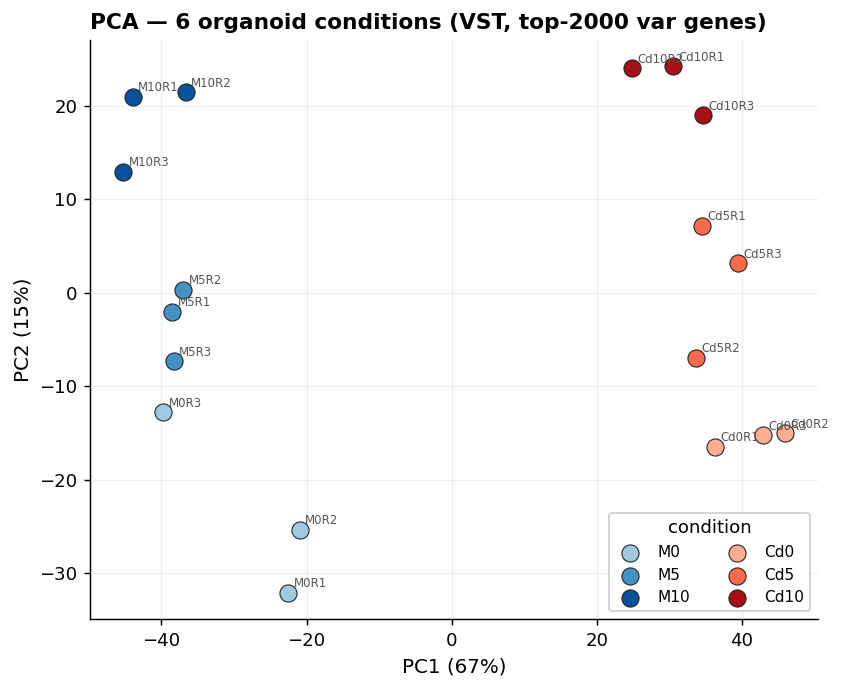

wrote /home/job37yv/Projects_shared/DECIDE_A04_CdiffOrganoid_Butyrate/results/overview_for_sara/PCA_6conditions.png

Interpretation hint: expect PC1 to separate Cd vs Mock (infection), PC2 to track butyrate dose.


In [4]:
from sklearn.decomposition import PCA
X=vst.T.values  # samples x genes
# top-2000 variable genes
v=vst.var(axis=1).sort_values(ascending=False)
top=v.index[:2000]
Xv=vst.loc[top].T.values
Xv=(Xv-Xv.mean(0))/ (Xv.std(0)+1e-9)
pca=PCA(n_components=5).fit(Xv); pcs=pca.transform(Xv)
ev=pca.explained_variance_ratio_*100

cond_col={'M0':'#9ecae1','M5':'#4292c6','M10':'#08519c','Cd0':'#fcae91','Cd5':'#fb6a4a','Cd10':'#a50f15'}
fig,ax=plt.subplots(figsize=(6.6,5.4))
for cond in COND_ORDER:
    idx=[i for i,s in enumerate(vst.columns) if samples.loc[s,'cond']==cond]
    ax.scatter(pcs[idx,0],pcs[idx,1],s=90,color=cond_col[cond],edgecolor='#222',lw=.6,label=cond,zorder=3)
for i,s in enumerate(vst.columns):
    ax.annotate(s, (pcs[i,0],pcs[i,1]), fontsize=6.5, color='#555', xytext=(3,3), textcoords='offset points')
ax.set_xlabel(f'PC1 ({ev[0]:.0f}%)',fontsize=11); ax.set_ylabel(f'PC2 ({ev[1]:.0f}%)',fontsize=11)
ax.set_title('PCA — 6 organoid conditions (VST, top-2000 var genes)',fontsize=12,fontweight='bold',loc='left')
ax.legend(title='condition',fontsize=8.5,ncol=2,framealpha=.9); ax.grid(alpha=.2)
plt.tight_layout(); fig.savefig(OUT/'PCA_6conditions.png'); plt.show()
print('wrote',OUT/'PCA_6conditions.png')
print('\nInterpretation hint: expect PC1 to separate Cd vs Mock (infection), PC2 to track butyrate dose.')

## 3. NF-κB pathway (+PPARG) heatmap — Hallmark ∪ KEGG ∪ Reactome

In [5]:
# --- gene sets. Prefer local GMTs if present; else use built-in curated fallback lists. ---
GMT_DIR = A04/'data/refs/genesets'   # put .gmt files here if you have them
def read_gmt_symbols(path, name_contains):
    hits=set()
    if not Path(path).exists(): return hits
    for line in open(path):
        parts=line.rstrip('\n').split('\t')
        if len(parts)<3: continue
        if name_contains.lower() in parts[0].lower():
            hits|=set(parts[2:])
    return hits

nfkb=set()
for gmt,key in [('h.all.v2024.1.Hs.symbols.gmt','HALLMARK_TNFA_SIGNALING_VIA_NFKB'),
                ('c2.cp.kegg.v2024.1.Hs.symbols.gmt','KEGG_NF_KAPPA_B'),
                ('c2.cp.reactome.v2024.1.Hs.symbols.gmt','REACTOME')]:
    nfkb|=read_gmt_symbols(GMT_DIR/gmt, key if 'REACTOME' not in key else 'NFKB')

# curated fallback (union of canonical NF-κB signalling members across the 3 DBs) if no GMTs found
if len(nfkb)<20:
    print('No local GMTs found — using curated NF-κB union fallback.')
    nfkb=set('''NFKB1 NFKB2 RELA RELB REL NFKBIA NFKBIB NFKBIE NFKBIZ IKBKB IKBKG CHUK
      TNF TNFAIP3 TNFAIP2 TRAF1 TRAF2 TRAF3 TRAF6 TRADD RIPK1 RIPK2 MAP3K7 TAB1 TAB2 TAB3
      IRAK1 IRAK2 IRAK4 MYD88 TLR2 TLR4 CD14 LY96 BIRC2 BIRC3 XIAP CFLAR
      CXCL1 CXCL2 CXCL3 CXCL8 CCL20 CCL2 IL1B IL6 PTGS2 NFKBIL1 BCL3 PLAU ICAM1 VCAM1
      LTA LTB CD40 CD40LG TNFRSF1A TNFRSF1B IKBKE TBK1 NFKB1 GADD45B EDN1 SOD2 CXCL10 CCL5'''.split())
nfkb.add('PPARG')   # requested add-on
panel=sorted([g for g in nfkb if g in vst_sym.index])
missing=sorted([g for g in nfkb if g not in vst_sym.index])
print(f'NF-κB(+PPARG) panel genes present: {len(panel)} | missing (not expressed/ID): {len(missing)}')
print('missing example:', missing[:12])

No local GMTs found — using curated NF-κB union fallback.
NF-κB(+PPARG) panel genes present: 59 | missing (not expressed/ID): 7
missing example: ['CCL2', 'CD40LG', 'IL6', 'LTA', 'LY96', 'PTGS2', 'VCAM1']


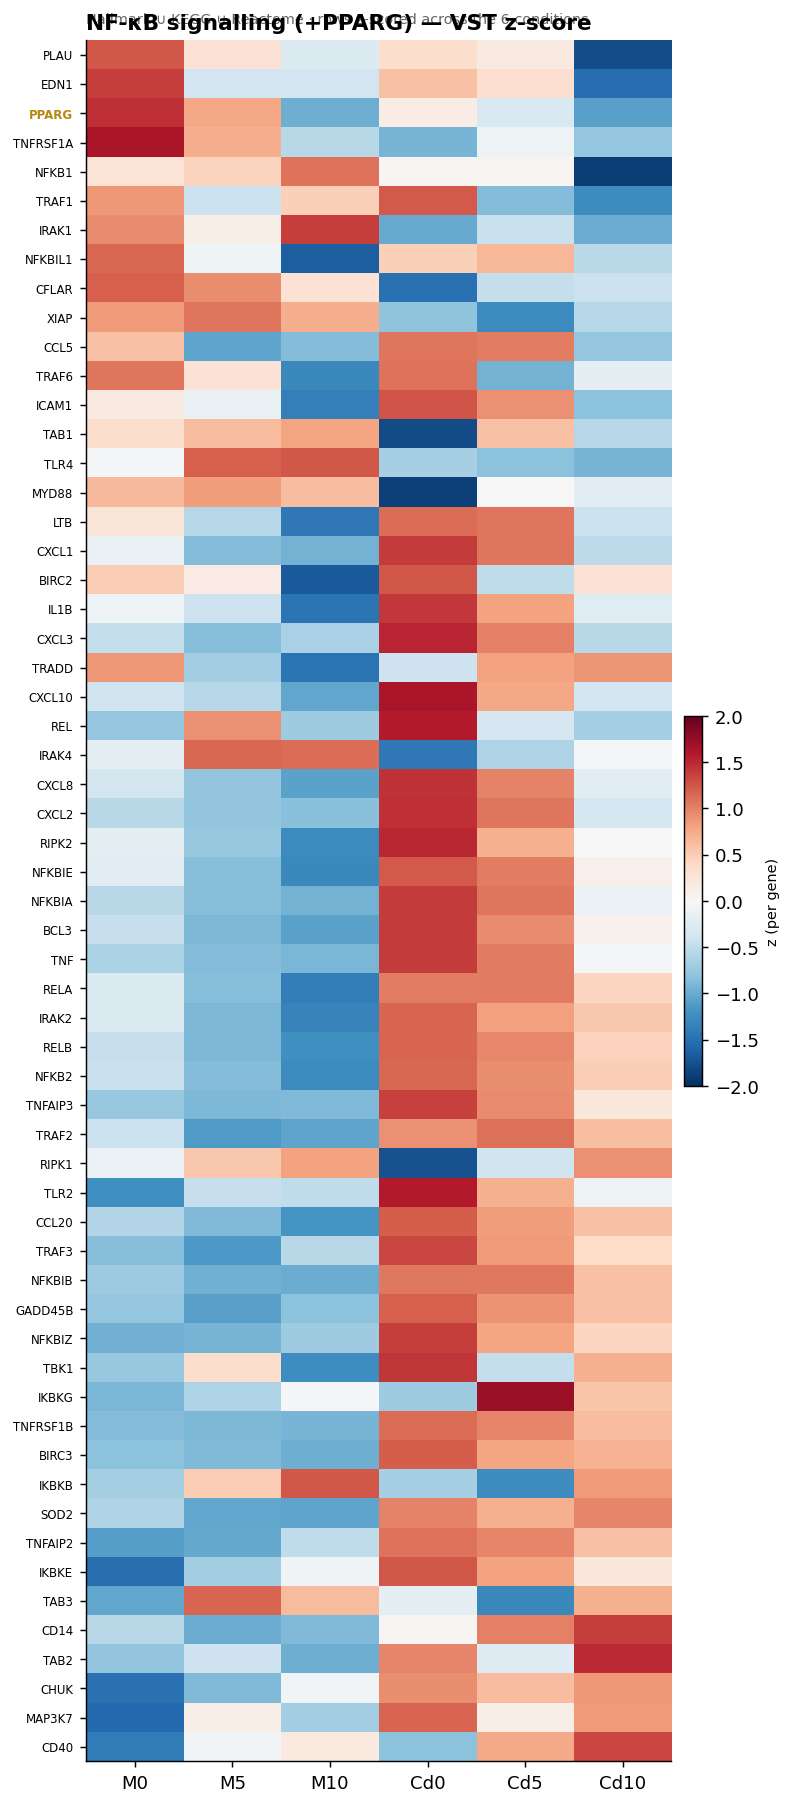

wrote /home/job37yv/Projects_shared/DECIDE_A04_CdiffOrganoid_Butyrate/results/overview_for_sara/heatmap_NFkB_PPARG.png


In [6]:
import matplotlib as mpl
# condition-mean VST, z-scored per gene
cond_means=pd.DataFrame({cond: vst_sym[[s for s in vst.columns if samples.loc[s,'cond']==cond]].mean(axis=1)
                         for cond in COND_ORDER})
M=cond_means.loc[panel]
Z=M.sub(M.mean(axis=1),axis=0).div(M.std(axis=1)+1e-9,axis=0)
# order genes by Cd10-minus-M0 pattern for readability
Z=Z.loc[(Z['Cd10']-Z['M0']).sort_values().index]

fig,ax=plt.subplots(figsize=(6.2, max(6,0.22*len(Z)+1)))
im=ax.imshow(Z.values, cmap='RdBu_r', vmin=-2, vmax=2, aspect='auto')
ax.set_xticks(range(len(COND_ORDER))); ax.set_xticklabels(COND_ORDER, fontsize=10)
ax.set_yticks(range(len(Z))); ax.set_yticklabels(Z.index, fontsize=6.5)
ax.set_title('NF-κB signalling (+PPARG) — VST z-score', fontsize=12, fontweight='bold', loc='left')
ax.text(0,1.01,'Hallmark ∪ KEGG ∪ Reactome · rows z-scored across the 6 conditions', transform=ax.transAxes, fontsize=8, color='#666')
cb=fig.colorbar(im,ax=ax,fraction=0.03,pad=0.02); cb.set_label('z (per gene)',fontsize=8)
# mark PPARG
if 'PPARG' in Z.index:
    yi=list(Z.index).index('PPARG'); ax.get_yticklabels()[yi].set_color('#b8860b'); ax.get_yticklabels()[yi].set_fontweight('bold')
plt.tight_layout(); fig.savefig(OUT/'heatmap_NFkB_PPARG.png'); plt.show()
print('wrote',OUT/'heatmap_NFkB_PPARG.png')

## 4. Top-regulated genes heatmap (data-driven)

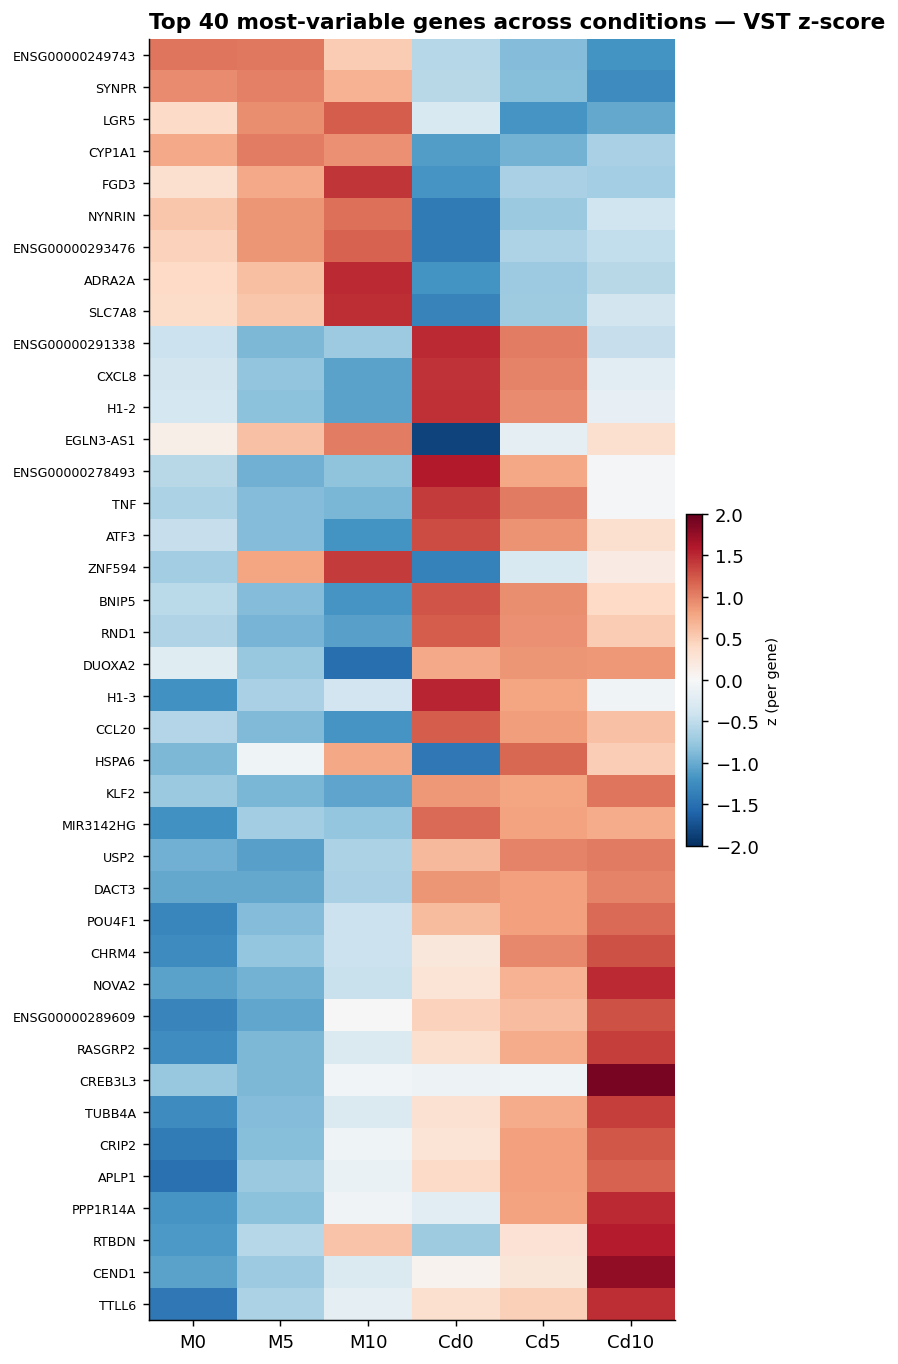

wrote /home/job37yv/Projects_shared/DECIDE_A04_CdiffOrganoid_Butyrate/results/overview_for_sara/heatmap_top_regulated.png


In [7]:
# top regulated = highest variance across the 6 condition means (VST), symbol-indexed
Mall=pd.DataFrame({cond: vst_sym[[s for s in vst.columns if samples.loc[s,'cond']==cond]].mean(axis=1)
                   for cond in COND_ORDER})
topN=40
sel=(Mall.max(axis=1)-Mall.min(axis=1)).sort_values(ascending=False).index[:topN]
Zt=Mall.loc[sel]; Zt=Zt.sub(Zt.mean(axis=1),axis=0).div(Zt.std(axis=1)+1e-9,axis=0)
Zt=Zt.loc[(Zt['Cd10']-Zt['M0']).sort_values().index]
fig,ax=plt.subplots(figsize=(6.2, max(6,0.24*len(Zt)+1)))
im=ax.imshow(Zt.values,cmap='RdBu_r',vmin=-2,vmax=2,aspect='auto')
ax.set_xticks(range(len(COND_ORDER))); ax.set_xticklabels(COND_ORDER,fontsize=10)
ax.set_yticks(range(len(Zt))); ax.set_yticklabels(Zt.index,fontsize=7)
ax.set_title(f'Top {topN} most-variable genes across conditions — VST z-score',fontsize=12,fontweight='bold',loc='left')
cb=fig.colorbar(im,ax=ax,fraction=0.03,pad=0.02); cb.set_label('z (per gene)',fontsize=8)
plt.tight_layout(); fig.savefig(OUT/'heatmap_top_regulated.png'); plt.show()
print('wrote',OUT/'heatmap_top_regulated.png')

## Results & interpretation (fill from the printed outputs / rendered figures)

**PCA.** With 3 replicates per condition the 18 points should group by condition. Expect **PC1 =
infection** (Cd conditions separating from Mock) and **PC2 = butyrate dose** (0→5→10 mM gradient
within each infection state). If the Cd points at 10 mM drift back toward Mock along PC1, that is the
butyrate-attenuates-infection signal, visible at the whole-transcriptome level. Tight replicate
clustering also serves as QC (no outlier libraries).

**NF-κB (+PPARG) heatmap.** Read left→right across the butyrate gradient within each infection block.
Expected: the chemokine/NF-κB output rows (CXCL1/2/3/8, CCL20, TNFAIP3, BIRC3) are high in **Cd0**
and cool down toward **Cd10** — the dose-dependent inflammatory brake. PPARG is highlighted (gold):
butyrate is a known PPAR-γ activator in colonocytes, so watch whether PPARG rises with dose — a
possible upstream node linking the metabolite to NF-κB suppression.

**Top-regulated heatmap.** Data-driven (most-variable genes) — shows the strongest signals without a
pathway prior; use it to spot programmes we haven't targeted yet (e.g. metabolic, stress).

### Further analyses Sara mentioned (ready when you are)
- GSEA/ORA on Hallmark/KEGG/Reactome per contrast (we have the machinery from A04).
- Per-gene dose-response plots for any hits from these overviews.
- The IL-8 / conditional-brake figures (already built) for the poster.

All three figures are saved in `results/overview_for_sara/`.